# Tweet Analysis OvR

Nom et prénom des membres du groupe :

* MOUSSA NIZAR Akidat
* NASSERA NABGAOUI
* EL AIDOUNI Chirine
* MAURIN Paul


##Introduction
Dans ce script nous avons tenté de faire une prédiction multi-label grâce à une stratégie de classification multiclasse de type On-vs-Rest (OvR) pour les tâches 2 et 3.

Le pré-traitement et la classification de la tâche 1 restent inchangés par rapport au fichier original scitweets.ipynb.

## Imports

In [5]:
!pip install emoji

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 608.4/608.4 kB 10.8 MB/s eta 0:00:00


In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import string
import re
import sqlite3
import warnings
from typing import Callable, Any
import sys
warnings.filterwarnings('ignore')

from collections import Counter
from google.colab import drive
import json

import nltk
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
nltk.download('punkt_tab', quiet=True)
nltk.download('stopwords', quiet=True)
nltk.download('wordnet', quiet=True)

import emoji

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.naive_bayes import ComplementNB
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.multiclass import OneVsRestClassifier
from sklearn.metrics import (classification_report, confusion_matrix,
                              ConfusionMatrixDisplay, accuracy_score,
                              precision_score, recall_score, f1_score)
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.preprocessing import MaxAbsScaler

from scipy.sparse import hstack, csr_matrix

import unicodedata

from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

print('Imports OK')

Imports OK


## Configuration
Chaque utilisateur doit définir le chemin d’accès correspondant à son espace Google Drive personnel.

In [7]:
!ls -la "/content/drive/Shareddrives"

ls: cannot access '/content/drive/Shareddrives': No such file or directory


In [8]:

drive.mount('/content/drive')
my_local_drive='/content/drive/MyDrive/Projet ML1 Master ICo'
sys.path.append(my_local_drive)

Mounted at /content/drive


## Raw Data

In [9]:
df = pd.read_csv(my_local_drive+'/scitweets_export.csv', na_values='na', sep="\t", index_col=0).reset_index(drop=True)
df_original = df.copy()
# on doit mettre le chemin qui emmene à notre dataset
# on met la colonne 0 en index et on reset l'index car on a vu qu'il n'est pas continu.


In [10]:
import os

print(f"Contents of my_local_drive ({my_local_drive}):")
if os.path.exists(my_local_drive):
    print(os.listdir(my_local_drive))
else:
    print(f"The directory '{my_local_drive}' does not exist.")

a_trier_path = '/content/drive/MyDrive/a trier/'
print(f"\nContents of '{a_trier_path}':")
if os.path.exists(a_trier_path):
    print(os.listdir(a_trier_path))
else:
    print(f"The directory '{a_trier_path}' does not exist.")


Contents of my_local_drive (/content/drive/MyDrive/Projet ML1 Master ICo):
['SciTweetsData.pdf', '3511808.3557693.pdf', 'Projet 2026 - Machine Learning I - HAI817-2.pdf', 'scitweets_export.csv', 'Document ML.gdoc', 'figures', 'Scitweets.ipynb', 'resultats_ml.json', 'Scitweets_OvR.ipynb']

Contents of '/content/drive/MyDrive/a trier/':
The directory '/content/drive/MyDrive/a trier/' does not exist.


In [11]:
df.head(10)

,tweet_id,text,science_related,scientific_claim,scientific_reference,scientific_context
0,316669998137483264,Knees are a bit sore. i guess that's a sign th...,0,0.0,0.0,0.0
1,319090866545385472,McDonald's breakfast stop then the gym 🏀💪,0,0.0,0.0,0.0
2,322030931022065664,Can any Gynecologist with Cancer Experience ex...,1,1.0,0.0,0.0
3,322694830620807168,Couch-lock highs lead to sleeping in the couch...,1,1.0,0.0,0.0
4,328524426658328576,Does daily routine help prevent problems with ...,1,1.0,0.0,0.0
5,331396203700944896,The Impact of Infertility on You and Your Rela...,0,0.0,0.0,0.0
6,333266791960809472,“Traffic Jam” In Brain’s Neurons Could Be Caus...,1,1.0,1.0,1.0
7,334282732085587968,Can playing more games improve lives and save ...,1,1.0,0.0,0.0
8,334350038090276864,The effect of climate change on iceberg produc...,1,0.0,1.0,1.0
9,335542235452014594,@HankAzaria @TheSimpsons oh loneliness and che...,0,0.0,0.0,0.0


In [12]:
df.dtypes

,0
tweet_id,int64
text,object
science_related,int64
scientific_claim,float64
scientific_reference,float64
scientific_context,float64


In [13]:
df.shape

(1140, 6)

In [14]:
df.describe()

,tweet_id,science_related,scientific_claim,scientific_reference,scientific_context
count,1.140000e+03,1140.000000,1140.000000,1140.00000,1140.000000
mean,8.560901e+17,0.328947,0.230702,0.17807,0.220175
std,2.865422e+17,0.470037,0.421467,0.38274,0.414547
min,3.166700e+17,0.000000,0.000000,0.00000,0.000000
25%,6.176042e+17,0.000000,0.000000,0.00000,0.000000
50%,8.615253e+17,0.000000,0.000000,0.00000,0.000000
75%,1.103864e+18,1.000000,0.000000,0.00000,0.000000
max,1.344485e+18,1.000000,1.000000,1.00000,1.000000


# 1. Analyse des données

##1.1 Répartition des classes.
Le jeu de données contient 1140 tweets.


Nous observons qu'environ 33% des tweets sont science_related tandis que 67% ne le sont pas. Ainsi, un modèle prédisant systématiquement la classe majoritaire (non-science_related) atteindrait une précision d’environ 67 %, sans réelle capacité à différencier les classes. Cela met en évidence un problème de déséquilibre des classes (imbalanced dataset).
Nous analysons à présent la répartition des sous-classes au sein des tweets identifiés comme scientifiques.

In [15]:
df.query("science_related == 1").describe()




,tweet_id,science_related,scientific_claim,scientific_reference,scientific_context
count,3.750000e+02,375.0,375.000000,375.000000,375.000000
mean,8.602661e+17,1.0,0.701333,0.541333,0.669333
std,2.899685e+17,0.0,0.458285,0.498954,0.471082
min,3.220309e+17,1.0,0.000000,0.000000,0.000000
25%,6.301684e+17,1.0,0.000000,0.000000,0.000000
50%,8.500253e+17,1.0,1.000000,1.000000,1.000000
75%,1.116759e+18,1.0,1.000000,1.000000,1.000000
max,1.340456e+18,1.0,1.000000,1.000000,1.000000


In [16]:
df.query("science_related == 1 & scientific_claim == 0 & scientific_reference == 0 & scientific_context == 0").describe()


,tweet_id,science_related,scientific_claim,scientific_reference,scientific_context
count,0.0,0.0,0.0,0.0,0.0
mean,NaN,NaN,NaN,NaN,NaN
std,NaN,NaN,NaN,NaN,NaN
min,NaN,NaN,NaN,NaN,NaN
25%,NaN,NaN,NaN,NaN,NaN
50%,NaN,NaN,NaN,NaN,NaN
75%,NaN,NaN,NaN,NaN,NaN
max,NaN,NaN,NaN,NaN,NaN


In [17]:
df.query("science_related == 0 & (scientific_claim == 1 | scientific_reference == 1 | scientific_context == 1)").describe()


,tweet_id,science_related,scientific_claim,scientific_reference,scientific_context
count,0.0,0.0,0.0,0.0,0.0
mean,NaN,NaN,NaN,NaN,NaN
std,NaN,NaN,NaN,NaN,NaN
min,NaN,NaN,NaN,NaN,NaN
25%,NaN,NaN,NaN,NaN,NaN
50%,NaN,NaN,NaN,NaN,NaN
75%,NaN,NaN,NaN,NaN,NaN
max,NaN,NaN,NaN,NaN,NaN


## 1.2. Sanity check

Dès le départ, un contrôle de cohérence est réalisé afin de vérifier la validité des hypothèses du jeu de données. Nous vérifions notamment que science_related = 1, au moins l’une des variables suivantes est égale à 1 : :

*   scientific_reference
*   scientific_claim
*   scientific_context

Cette propriété est vérifiée sur l’ensemble des données. Par ailleurs, l’absence de doublons dans les identifiants des tweets est confirmée ce qui garantit la qualité des données.

In [18]:
print("nombre de doublons : ", df.duplicated("tweet_id").sum())

nombre de doublons :  0


##1.3 Analyse de la différence de longueur de tweets
Une analyse a été menée sur la longueur des tweets. Il semble que la longueur des tweets soit représentative de la classe.
La longueur en nb_char est plus représentative (14.0% plus élevée en moyenne pour 1 p/r à 0) que la longueur en nb_mots (5.7%), la longueur moyenne des mots est 10% plus élevée chez les science_related.

In [19]:
## calcul de la longueur des tweets en char/mots et longueur moyenne des mots

def count_words (text:str)-> int :
    return len(text.split())

def count_chars (text:str)-> int :
  return len(text)

def long_moy_mots (text:str)-> float :
  return len(text)/len(text.split())

df['nb_words'] = df['text'].apply(count_words)
df['nb_chars'] = df['text'].apply(count_chars)
df['mean_len_words'] = df['text'].apply(long_moy_mots)

df[['text','nb_words', 'nb_chars','mean_len_words']].head(20)


,text,nb_words,nb_chars,mean_len_words
0,Knees are a bit sore. i guess that's a sign th...,16,82,5.125000
1,McDonald's breakfast stop then the gym 🏀💪,7,41,5.857143
2,Can any Gynecologist with Cancer Experience ex...,21,139,6.619048
3,Couch-lock highs lead to sleeping in the couch...,13,75,5.769231
4,Does daily routine help prevent problems with ...,10,85,8.500000
5,The Impact of Infertility on You and Your Rela...,10,77,7.700000
6,“Traffic Jam” In Brain’s Neurons Could Be Caus...,13,106,8.153846
7,Can playing more games improve lives and save ...,16,118,7.375000
8,The effect of climate change on iceberg produc...,12,95,7.916667
9,@HankAzaria @TheSimpsons oh loneliness and che...,10,76,7.600000


In [20]:
print('Moyenne et Écart-type du nb_mots groupby', df.groupby(["science_related"])["nb_words"].agg(['mean','std']))

print('\nMoyenne et Écart-type du nb_chars groupby',df.groupby(["science_related"])["nb_chars"].agg(['mean','std']))

print('\nMoyenne et Écart-type du long_moy_mots groupby',df.groupby(["science_related"])['mean_len_words'].agg(['mean','std']))


Moyenne et Écart-type du nb_mots groupby                       mean        std
science_related                      
0                18.870588  10.001321
1                19.952000  11.099590

Moyenne et Écart-type du nb_chars groupby                        mean        std
science_related                       
0                130.969935  64.637089
1                149.336000  78.240266

Moyenne et Écart-type du long_moy_mots groupby                      mean       std
science_related                    
0                7.172719  1.550427
1                7.809144  1.576751


#2. Pré-traitement des données
Le texte brut doit être transformé afin de pouvoir être exploité par les modèles de machine learning.
Nous appliquons un pipeline de nettoyage en plusieurs étapes.
## 2.1 Parsing et nettoyage du texte

Séquentiellement

1. Identifier les emojis: compter puis supprimer
2. Identifier les hashtags: compter puis supprimer
3. Identifier les @: compter puis supprimer
4. Identifier les liens: compter et supprimer
5. Remove stop words (vérifier si langue anglaise)
6. Remove non ascii caractères
7. Identifier s'il y a un chiffre ou un nombre hors id dans les #
8. identifier s'il y a des poncutations spécifiques comme ?    

##2.1. Emojis
###2.1.1. Identification des emojis

In [21]:
## Identifier les emojis: compter puis supprimer


def count_emojis(text: str) -> int:
  return sum(1 for ch in text if ch in emoji.EMOJI_DATA)

def remove_emoji(text: str) -> str:
    return "".join(ch for ch in text if ch not in emoji.EMOJI_DATA)

def treat_emoji(df):
    df['nb_emoji'] = df['text'].apply(count_emojis)
    df['text_cleaned']=df['text_cleaned'].apply(remove_emoji)
    return df


df['nb_emoji'] = df['text'].apply(count_emojis)


###2.1.2 Elimination des émojis du text_clean

> Ajouter une citation


On retire simplement tous les émojis

In [22]:
df['text_cleaned']=df['text'].apply(remove_emoji)

print("Emojis restantes :" , df['text_cleaned'].apply(count_emojis).sum())

Emojis restantes : 0


##2.2. Hastags
Les symboles # sont identifiés dans le texte. Les hashtags sont des éléments fréquents dans les tweets et peuvent contenir des informations utiles.
Dans notre approche, nous choisissons de conserver le contenu du hashtag tout en supprimant uniquement le symbole "#". Cela permet de garder les mots associés tout en standardisant le texte.
###2.2.1. Identification des \#

In [23]:
## Identifier les # et : compter puis supprimer

def count_hastag(text: str) -> int:
  return sum(1 for ch in text if ch =='#')

## ici il faut se demander si on retire tout le contenu du hashtag ou simplement le symbole #

def remove_hashtag(text: str) -> str:
    return "".join(ch for ch in text if ch !='#')

def treat_hashtag(df):
  df['nb_hashtag'] = df['text'].apply(count_hastag)
  df['text_cleaned']=df['text_cleaned'].apply(remove_hashtag)
  return df

#df[['text','nb_words', 'nb_chars','mean_len_words','nb_hashtag', 'science_related']].head(20)

###2.2.2 Elimination des \# du text_clean
Finalement, seul le symbole # est supprimé, tandis que le contenu du hashtag est conservé afin de préserver le sens du tweet.

In [24]:
print("Hastag restants :" , df['text_cleaned'].apply(count_hastag).sum())

Hastag restants : 734


##2.3. Traitement des @
Les symboles @ sont identifiés dans le texte. Les mentions @ sont supprimées intégralement car elles n’apportent
pas d’information pertinente pour la tâche de classification. Ce choix permet de réduire le bruit dans les données.
###2.3.1 Identification des @

In [25]:
## Identifier les @ et : compter puis supprimer

def count_arobases(text: str) -> int:
  return len(re.findall(r"@[^\s]+", text))

## ici on retire tout le contenu du arobase

def remove_arobases(text: str) -> str:
  # Supprimer @ + tous les caractères non-espace qui suivent
  cleaned = re.sub(r'@[^\s]+', '', text)
  # Optionnel : nettoyer les espaces multiples
  cleaned = re.sub(r'\s{2,}', ' ', cleaned).strip()
  return cleaned

def treat_arobase(df):
  df['nb_arobases'] = df['text'].apply(count_arobases)
  df['text_cleaned']=df['text_cleaned'].apply(remove_arobases)
  return df

#df[['text','text_cleaned', 'nb_words', 'nb_chars','mean_len_words', 'nb_arobases']].head(20)

###2.3.2. Elimination des @ du text_clean

La variabilité des @ref est très grande, nous retrouvons peu de @ref redondants.
Nous retirons donc les @ref en entier contrairement aux #ref.

In [26]:
#df['text_cleaned']=df['text_cleaned'].apply(remove_arobases)
print("@ restantes :" , df['text_cleaned'].apply(count_arobases).sum())


@ restantes : 762


In [27]:
#df["is_arobase"]  = df.apply(lambda row: 1 if "@" in row["text_cleaned"] else 0, axis=1)
#df.query("is_arobase == 1")[["text","nb_arobases"]]

##2.4. Traitement des liens
Les liens sont détectés à l’aide d’expressions régulières puis supprimés.
Bien qu’un lien puisse indiquer un contenu informatif, sa forme brute n’est pas directement exploitable par les modèles.
###2.4.1 Identification des liens

In [28]:
## Identifier les liens et : compter puis supprimer

def count_links(text: str) -> int:
  return len(re.findall(r'(https?://)?[a-zA-Z0-9.-]+\.[a-zA-Z]{2,}(/[^\s]*)?', text))

# Suppression des liens

def remove_links(text: str) -> int:
  return re.sub(r'(https?://)?[a-zA-Z0-9.-]+\.[a-zA-Z]{2,}(/[^\s]*)?',"", text)

def treat_links(df):
  df['nb_links'] = df['text'].apply(count_links)
  df['text_cleaned']=df['text_cleaned'].apply(remove_links)
  return df

print(df.query("tweet_id==710072387220475904")['text'].apply(remove_links))

#df[['text','text_cleaned', 'nb_words', 'nb_chars','mean_len_words','nb_hastag', 'nb_arobases', 'nb_links']].head(20)

396    CGA for the non-specialist  from @JohnGladman1...
Name: text, dtype: object


##2.5. Retrait des non-ASCII
Les caractères non-ASCII sont supprimés.
Cette étape permet d’éliminer les symboles ou écritures non pertinentes pour l’analyse linguistique.

In [29]:
def remove_non_ASCII(text: str) -> str:
  return re.sub(r'[^\w\s]', '', text)

def treat_non_ascii(df):
  df["text_cleaned"] = df.apply(lambda row: remove_non_ASCII(row['text_cleaned']), axis=1)
  return df

treat_non_ascii(df)

,tweet_id,text,science_related,scientific_claim,scientific_reference,scientific_context,nb_words,nb_chars,mean_len_words,nb_emoji,text_cleaned
0,316669998137483264,Knees are a bit sore. i guess that's a sign th...,0,0.0,0.0,0.0,16,82,5.125000,0,Knees are a bit sore i guess thats a sign that...
1,319090866545385472,McDonald's breakfast stop then the gym 🏀💪,0,0.0,0.0,0.0,7,41,5.857143,2,McDonalds breakfast stop then the gym
2,322030931022065664,Can any Gynecologist with Cancer Experience ex...,1,1.0,0.0,0.0,21,139,6.619048,0,Can any Gynecologist with Cancer Experience ex...
3,322694830620807168,Couch-lock highs lead to sleeping in the couch...,1,1.0,0.0,0.0,13,75,5.769231,0,Couchlock highs lead to sleeping in the couch ...
4,328524426658328576,Does daily routine help prevent problems with ...,1,1.0,0.0,0.0,10,85,8.500000,0,Does daily routine help prevent problems with ...
...,...,...,...,...,...,...,...,...,...,...,...
1135,1340455669443350528,@LaylaFanucci @realDonaldTrump I'm sorry but w...,1,1.0,0.0,0.0,43,242,5.627907,0,LaylaFanucci realDonaldTrump Im sorry but we D...
1136,1340689510569549824,"Dear #NIN applicants, you can kindly download ...",0,0.0,0.0,0.0,39,274,7.025641,1,Dear NIN applicants you can kindly download th...
1137,1341155832793165825,Whats the uber support team email address?,0,0.0,0.0,0.0,7,42,6.000000,0,Whats the uber support team email address
1138,1344167355648241664,House passes bill to increase stimulus checks ...,0,0.0,0.0,0.0,10,79,7.900000,0,House passes bill to increase stimulus checks ...


In [30]:
df[['text','text_cleaned']].head(30)

,text,text_cleaned
0,Knees are a bit sore. i guess that's a sign th...,Knees are a bit sore i guess thats a sign that...
1,McDonald's breakfast stop then the gym 🏀💪,McDonalds breakfast stop then the gym
2,Can any Gynecologist with Cancer Experience ex...,Can any Gynecologist with Cancer Experience ex...
3,Couch-lock highs lead to sleeping in the couch...,Couchlock highs lead to sleeping in the couch ...
4,Does daily routine help prevent problems with ...,Does daily routine help prevent problems with ...
5,The Impact of Infertility on You and Your Rela...,The Impact of Infertility on You and Your Rela...
6,“Traffic Jam” In Brain’s Neurons Could Be Caus...,Traffic Jam In Brains Neurons Could Be Cause O...
7,Can playing more games improve lives and save ...,Can playing more games improve lives and save ...
8,The effect of climate change on iceberg produc...,The effect of climate change on iceberg produc...
9,@HankAzaria @TheSimpsons oh loneliness and che...,HankAzaria TheSimpsons oh loneliness and chees...


##3.3.Tokenisation
Le texte est ensuite transformé en séquences de mots via :

*   tokenisation (découpage en mots)
*   suppression des stop words
*   lemmatisation (ramener les mots à leur forme de base)

In [31]:

lemmatizer = WordNetLemmatizer()

def lemmatize_text(texts):
    return [lemmatizer.lemmatize(w) for w in texts]


print("Original:", df['text_cleaned'].iloc[0])
#print("Lemmatisé:", df['text_lemmatized'].iloc[0])

Original: Knees are a bit sore i guess thats a sign that my recent treadmilling is working


In [32]:
import string
import re
import emoji
from nltk.stem import WordNetLemmatizer
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
import nltk

nltk.download('punkt_tab')
nltk.download('stopwords')
nltk.download('wordnet')

lemmatizer = WordNetLemmatizer()

def lemmatize_text(texts):
    return [lemmatizer.lemmatize(w) for w in texts]

def remove_stopwords(words: list[str]):
    stop_words = set(stopwords.words('english'))
    return [word for word in words if word not in stop_words]

def remove_punctuation(text):
    return "".join([char for char in text if char not in string.punctuation])

def remove_emoji(text: str) -> str:
    return "".join(ch for ch in text if ch not in emoji.EMOJI_DATA)

def treat_emoji(df):
    df['nb_emoji'] = df['text'].apply(lambda t: sum(1 for ch in t if ch in emoji.EMOJI_DATA))
    df['text_cleaned'] = df['text_cleaned'].apply(remove_emoji)
    return df

def treat_hashtag(df):
    df['nb_hashtag'] = df['text'].apply(lambda t: t.count('#'))
    df['text_cleaned'] = df['text_cleaned'].apply(lambda t: re.sub(r'#\S+', '', t))
    return df

def treat_arobase(df):
    df['nb_arobases'] = df['text'].apply(lambda t: len(re.findall(r'@[^\s]+', t)))
    df['text_cleaned'] = df['text_cleaned'].apply(lambda t: re.sub(r'@[^\s]+', '', t))
    return df

def treat_links(df):
    df['nb_links'] = df['text'].apply(lambda t: len(re.findall(r'https?://\S+', t)))
    df['text_cleaned'] = df['text_cleaned'].apply(lambda t: re.sub(r'https?://\S+', '', t))
    return df

def treat_non_ascii(df):
    df['text_cleaned'] = df['text_cleaned'].apply(lambda t: re.sub(r'[^\w\s]', '', t))
    return df

def main_pre_treatment(df):
    df = df.copy()
    df['text_cleaned'] = df['text'].copy()
    df = treat_arobase(df)
    df = treat_hashtag(df)
    df = treat_links(df)
    df = treat_emoji(df)
    df = treat_non_ascii(df)
    df['text_cleaned'] = df['text_cleaned'].str.lower()
    df['text_cleaned'] = df['text_cleaned'].apply(lambda t: re.sub(r'\s+', ' ', t).strip())
    df['text_cleaned'] = df['text_cleaned'].apply(remove_punctuation)
    df['text_tokenized'] = df['text_cleaned'].apply(lambda t: word_tokenize(t))
    df['text_tokenized'] = df['text_tokenized'].apply(remove_stopwords)
    df['text_tokenized'] = df['text_tokenized'].apply(lemmatize_text)
    df['text_lemmatized'] = df['text_tokenized'].apply(lambda tokens: " ".join(tokens))
    return df

# Chargement
df = pd.read_csv(my_local_drive + '/scitweets_export.csv', na_values='na', sep="\t", index_col=0).reset_index(drop=True)
df_original = df.copy()

# Preprocessing
df_clean = main_pre_treatment(df_original)
print(f"Dataset prêt : {df_clean.shape}")

# Vectorisation
from sklearn.feature_extraction.text import TfidfVectorizer
tfidf = TfidfVectorizer(max_features=5000, ngram_range=(1, 2), sublinear_tf=True)
X_all = tfidf.fit_transform(df_clean['text_lemmatized'])
print(f"Shape matrice TF-IDF : {X_all.shape}")

[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


Dataset prêt : (1140, 13)
Shape matrice TF-IDF : (1140, 5000)


On utilise TF-IDF avec bigrammes (unigrammes + bigrammes) et 5000 features max.
TF-IDF est plus adapté aux classifieurs sklearn que TextVectorization de Keras.

In [33]:
tfidf = TfidfVectorizer(max_features=5000, ngram_range=(1, 2), sublinear_tf=True)
X_all = tfidf.fit_transform(df_clean['text_lemmatized'])
print(f"Shape matrice TF-IDF : {X_all.shape}")
print(f"   Exemple de features : {tfidf.get_feature_names_out()[:20]}")

Shape matrice TF-IDF : (1140, 5000)
   Exemple de features : ['04' '10' '10 1296' '10 minute' '10 year' '100' '100 ebooks'
 '100 powered' '100 retweet' '100 story' '1000' '1000 death' '1000 wave'
 '10000' '10000 time' '11' '12' '1200' '1230' '128']


## Commentaires:
- Il est important de noter que l’ajustement (fit) du TF-IDF sur l’ensemble du dataset entraîne un phénomène de data leakage (fuite de données) ce qui biaise les performances du modèle.
Par conséquent, le TF-IDF doit être ajusté uniquement sur le train (données d’entraînement).

- Il est préférable d'utiliser l'argument min_df et max_df dans la classe TfIdfVectorizer qui permet d'éliminer des mots trop peu fréquent ou trop fréquent, ce qui vient limiter le nombre de mot de notre vocabulaire

- Nous observons, à partir de la cellule précédente, que notre nettoyage reste incomplet. En effet, de nombreux chiffres sont encore présents. Pris individuellement, ces chiffres présentent peu d’intérêt ; toutefois, leur suppression entraînerait une perte d’information.

- Le nettoyage des stops words supprime les négations, ce qui peux changer le sens de la phrase. Il faut donc conserver l'information.

- Certains tweets comportent des caractères provenant d’écritures non latines comme le chinois. Afin d’assurer une meilleure cohérence du texte, nous filtrons ces caractères pour ne conserver que ceux de l’alphabet latin.

- Il ne faut pas oublier après avoir fait le tf-idf de joindre avec les features numériques. ATTENTION: le résultat de tf-idf produit des valeurs entre 0 et 1. Du coup, les données de comptages sont entre [0, +infini], il faut donc appliquer une normalisation sur les données de comptages sinon les modèles de type logReg seront dominés par les features numériques. En revanche, pas besoin pour les modèles de type arbre. Comme TF-IDF produit des données sparses (profusion de zéro), il est préférable d'utiliser `MaxAbsScaler`

- Gestion du déséquilibre des classes en fonction du type de problème (classification binaire/multi-label)

In [34]:


NEG_KEEP = {"not", "no", "nor", "never", "n't", "cannot"}
STOPWORDS = set(stopwords.words('english'))
STOPWORDS_WTH_NEGATIVE =  STOPWORDS - NEG_KEEP

def _is_latin_or_neutral(ch: str) -> bool:
    """True si le caractere est latin (a-z, A-Z, eaeae...), un chiffre,
    ou un caractere neutre (espace, ponctuation). False pour les ecritures
    non-latines (coreen, chinois, cyrillique, arabe, ...)."""
    if not ch.isalnum():
        return True
    try:
        name = unicodedata.name(ch)
    except ValueError:
        return False
    return ('LATIN' in name) or ('DIGIT' in name)

def remove_non_latin(text: str) -> str:
    #Retire les caracteres d'ecritures non-latines (ex: chinois, etc.)
    return ''.join(ch for ch in text if _is_latin_or_neutral(ch))

def main_pre_treatment_v2(df, use_numeric_features: bool = True, use_special_tokens: bool = True, filter_non_latin: bool = True, keep_negations: bool = True, use_lemmatization: bool = True):
    df_ps = df.copy()

    # Création des features numériques -> comptage
    if use_numeric_features:
        df_ps['nb_links']        = df_ps['text'].apply(lambda t: len(re.findall(r'https?://\S+', t)))
        df_ps['nb_arobases']     = df_ps['text'].apply(lambda t: len(re.findall(r'@[^\s]+', t)))
        df_ps['nb_hashtag']      = df_ps['text'].apply(lambda t: t.count('#'))
        df_ps['nb_emoji']        = df_ps['text'].apply(lambda t: sum(1 for c in t if c in emoji.EMOJI_DATA))
        df_ps['has_question']    = df_ps['text'].str.contains(r'\?', regex=True).astype(int)
        df_ps['has_exclamation'] = df_ps['text'].str.contains(r'!', regex=True).astype(int)
        df_ps['nb_uppercase']    = df_ps['text'].apply(lambda t: len(re.findall(r'\b[A-Z]{3,}\b', t)))

    # Substitutions par des tokens spécifiques
    text = df_ps['text'].copy()

    if use_special_tokens:
        text = text.apply(lambda t: re.sub(r'https?://\S+', ' urltoken ', t))
        text = text.apply(lambda t: re.sub(r'@[^\s]+', ' usertoken ', t))
        text = text.apply(lambda t: re.sub(r'#(\w+)', r' \1 ', t))
        text = text.apply(lambda t: ''.join(c for c in t if c not in emoji.EMOJI_DATA))
        text = text.apply(lambda t: re.sub(r'\b\d+(?:[.,]\d+)?\s*%', ' pcttoken ', t))
        text = text.apply(lambda t: re.sub(r'\b(?:19|20)\d{2}\b', ' yeartoken ', t))
        text = text.apply(lambda t: re.sub(r'\b\d+(?:[.,]\d+)?\b', ' numtoken ', t))

    # Retrait des caracteres non-latins (ex: chinois)

    if filter_non_latin:
        text = text.apply(remove_non_latin)

    # Normalisation
    text = text.str.lower()
    text = text.apply(lambda t: t.translate(str.maketrans('', '', string.punctuation)))
    text = text.apply(lambda t: re.sub(r'[^\w\s]', '', t))
    text = text.apply(lambda t: re.sub(r'\s+', ' ', t).strip())
    df_ps['text_cleaned'] = text


    # Tokenisation, stop-words, lemmatisation
    tokens = df_ps['text_cleaned'].apply(word_tokenize)
    stop_words_set = STOPWORDS_WTH_NEGATIVE if keep_negations else STOPWORDS
    tokens = tokens.apply(lambda ws: [w for w in ws if w not in stop_words_set])

    if use_lemmatization:
        tokens = tokens.apply(lambda ws: [lemmatizer.lemmatize(w) for w in ws])

    df_ps['text_tokenized'] = tokens
    df_ps['text_lemmatized'] = tokens.apply(lambda t: ' '.join(t))
    return df_ps

In [35]:
df_clean = main_pre_treatment_v2(df)

In [36]:
for idx in [6, 13, 1, 11, 14,1139]:
    print(f'--- tweet [{idx}] ---')
    print(f'  ORIGINAL : {df["text"].iloc[idx]}')
    print(f'  LEMMA    : {df_clean["text_lemmatized"].iloc[idx]}')
    print()

--- tweet [6] ---
  ORIGINAL : “Traffic Jam” In Brain’s Neurons Could Be Cause Of Statin-Related Cognitive Decline http://t.co/kQ3XPdePKX
  LEMMA    : traffic jam brain neuron could cause statinrelated cognitive decline urltoken

--- tweet [13] ---
  ORIGINAL : http://t.co/eJlnUg0Gog Pay attention to classification essays format
  LEMMA    : urltoken pay attention classification essay format

--- tweet [1] ---
  ORIGINAL : McDonald's breakfast stop then the gym 🏀💪
  LEMMA    : mcdonalds breakfast stop gym

--- tweet [11] ---
  ORIGINAL : @bpkelly12 if that damn book lady decides to stop being a fuckin retard ill be out of here in 2 days
  LEMMA    : usertoken damn book lady decides stop fuckin retard ill numtoken day

--- tweet [14] ---
  ORIGINAL : @RepCohen @SenAlexander @SenBobCorker pls support #NIH funding to help fight #pancreaticcancer @PanCAN @PanCANMemphis #ifight4MyDad
  LEMMA    : usertoken usertoken usertoken pls support nih funding help fight pancreaticcancer usertoken use

Après le pré-traitement, si nous appliquons un tf-idf sur l'ensemble du dataframe, nous obtenons 2138 colonnes, ce qui représente une diminution de 57.24% de la taille du vocabulaire suite à une refonte du `main_pre_treatment` et à l'ajout des paramètres `min_df` et `max_df`

### Différentes combinaisons et cas possibles



<b>Comparaison de 4 configurations</b>:

| Config | Texte | Ajout des features Numerique |
|---|---|---|
| **A** | TF-IDF (seul) -> Baseline | Non |
| **B** | TF-IDF avec tokens speciaux | Oui (`nb_links`, `nb_emoji`...)  |
| **C** | TF-IDF | Oui (`nb_links`, `nb_emoji`...)  |
| **D** | Embedding denses | Pas besoin |



<i>On appelle tokens spéciaux, le remplacement des url par 'urltoken'.</i>

In [37]:
RANDOM_STATE = 42
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

class TextPreprocessor(BaseEstimator, TransformerMixin):

    def __init__(self, callback: Callable[pd.DataFrame, pd.DataFrame] = None, callback_kwargs: dict[str, Any] = None):
        # On passera dans la callback la référence de la fonction qui réalise le preprocessing, exemple main_pre_treatment
        self.callback = callback
        self.callback_kwargs = callback_kwargs

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        kwargs = self.callback_kwargs or {}
        df_out =  self.callback(X, **kwargs)
        return df_out['text_lemmatized'].values

## Modélisation Science vs Non Science

Le déséquilibre des classes est traité via différentes techniques :
*   pondération des classes (class_weight = 'balanced')
*   suréchantillonnage avec SMOTE

Ces approches permettent d’améliorer les performances sur les classes minoritaires.

Pour ce faire, plusieurs modèles de machine learning sont testés :

*   Régression logistique
*   SVC linéaire
*   Random Forest
*   Naive Bayes
*   k-NN
*   Réseaux de neurones (MLP)

Une validation croisée stratifiée à 5 fold est mise en place.

#### Baseline Model

In [38]:
def make_pipeline(class_weight=None):
    """Pipeline : TF-IDF -> [sampler] -> classifieur. Les hyperparams sont
    fixes par GridSearchCV via param_grid.

    class_weight peut etre None ou 'balanced' pour gerer le desequilibre des classes
    au niveau du classifieur.
    """
    return ImbPipeline([
        ('tfidf',   TfidfVectorizer(max_features=5000, ngram_range=(1, 2),
                                     sublinear_tf=True, min_df=2, max_df=0.95)),
        ('sampler', 'passthrough'),
        ('clf',     LogisticRegression(max_iter=2000, random_state=RANDOM_STATE,
                                         class_weight=class_weight)),
    ])

Pipeline : TF-IDF -> sampler -> classifieur.

Les hyperparams sont fixés par GridSearchCV via param_grid.

class_weight peut etre None ou 'balanced' pour gérer le déséquilibre des classes au niveau du classifieur.

In [39]:
df_clean = main_pre_treatment_v2(df_original,
                                  use_numeric_features=False,
                                  use_special_tokens=False,
                                  filter_non_latin=False,
                                  keep_negations=False,
                                  use_lemmatization=True)

X = df_clean['text_lemmatized']
y = df_clean['science_related'].values

print(f'Total tweets : {len(X)}')
print(f'Distribution y : NON-SCI={np.sum(y==0)}, SCI={np.sum(y==1)} (ratio = {np.sum(y==1)/len(y):.1%})')

# Split stratifie 80/20, la stratification est très importante ici afin de s'assurer que l'on dispose bien des observations de la classe minoritaire dans le jeu de train et de test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)
print(f'\nTrain : {len(X_train)} tweets')
print(f'Test  : {len(X_test)} tweets')

print(f'Total tweets : {len(X_train)}')
print(f'Distribution y : NON-SCI={np.sum(y_train==0)}, SCI={np.sum(y_train==1)} (ratio = {np.sum(y_train==1)/len(y_train):.1%})')

# Pipeline : TF-IDF -> [sampler='passthrough'] -> LogReg
# Pour cette premiere passe : class_weight=None (pas de correction du desequilibre), mettre class_weight='balanced' pour voir l'effet sur le recall de la classe minoritaire.
pipe = make_pipeline(class_weight=None)

pipe.fit(X_train, y_train)
y_pred = pipe.predict(X_test)

print(f'\nShape TF-IDF train : {pipe.named_steps["tfidf"].transform(X_train).shape}')
print(f'Shape TF-IDF test  : {pipe.named_steps["tfidf"].transform(X_test).shape}')

Total tweets : 1140
Distribution y : NON-SCI=765, SCI=375 (ratio = 32.9%)

Train : 912 tweets
Test  : 228 tweets
Total tweets : 912
Distribution y : NON-SCI=612, SCI=300 (ratio = 32.9%)

Shape TF-IDF train : (912, 1615)
Shape TF-IDF test  : (228, 1615)


### Résultat du modèle baseline

              precision    recall  f1-score   support

     NON-SCI       0.77      0.98      0.86       153
         SCI       0.91      0.39      0.54        75

    accuracy                           0.79       228
   macro avg       0.84      0.68      0.70       228
weighted avg       0.81      0.79      0.76       228



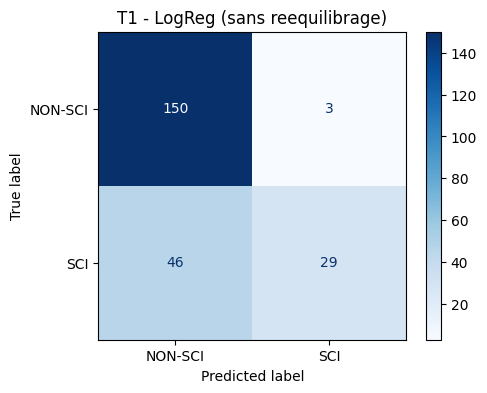

In [40]:
print(classification_report(y_test, y_pred, target_names=['NON-SCI', 'SCI']))

# Matrice de confusion
fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred),
                       display_labels=['NON-SCI', 'SCI']).plot(ax=ax, cmap='Blues')
ax.set_title('T1 - LogReg (sans reequilibrage)')
plt.show()

### Tf-idf avec le nettoyage et les ajouts

In [41]:
df_clean = main_pre_treatment_v2(df_original,
                                  use_numeric_features=True,
                                  use_special_tokens=True,
                                  filter_non_latin=True,
                                  keep_negations=True,
                                  use_lemmatization=True)

# Donnees pour T1
X_t1 = df_clean['text_lemmatized']
y_t1 = df_clean['science_related'].values

print(f'Total tweets : {len(X_t1)}')
print(f'Distribution y_t1 : NON-SCI={np.sum(y_t1==0)}, SCI={np.sum(y_t1==1)} (ratio = {np.sum(y_t1==1)/len(y_t1):.1%})')

# Split stratifie 80/20
X_train, X_test, y_train, y_test = train_test_split(
    X_t1, y_t1, test_size=0.2, stratify=y_t1, random_state=RANDOM_STATE
)
print(f'\nTrain : {len(X_train)} tweets')
print(f'Test  : {len(X_test)} tweets')
print(f'Distribution y_train : NON-SCI={np.sum(y_train==0)}, SCI={np.sum(y_train==1)} (ratio = {np.sum(y_train==1)/len(y_train):.1%})')

# Pipeline : TF-IDF -> [sampler='passthrough'] -> LogReg
# Pour cette premiere passe : class_weight=None (pas de correction du desequilibre).
# Mettre class_weight='balanced' pour voir l'effet sur le recall de la classe minoritaire.
pipe = make_pipeline(class_weight='balanced')

pipe.fit(X_train, y_train)
y_pred = pipe.predict(X_test)

# Sanity check : shape de la matrice TF-IDF apres fit
print(f'\nShape TF-IDF train : {pipe.named_steps["tfidf"].transform(X_train).shape}')
print(f'Shape TF-IDF test  : {pipe.named_steps["tfidf"].transform(X_test).shape}')

Total tweets : 1140
Distribution y_t1 : NON-SCI=765, SCI=375 (ratio = 32.9%)

Train : 912 tweets
Test  : 228 tweets
Distribution y_train : NON-SCI=612, SCI=300 (ratio = 32.9%)

Shape TF-IDF train : (912, 1714)
Shape TF-IDF test  : (228, 1714)


=== Classification report ===
              precision    recall  f1-score   support

     NON-SCI       0.89      0.88      0.88       153
         SCI       0.75      0.77      0.76        75

    accuracy                           0.84       228
   macro avg       0.82      0.82      0.82       228
weighted avg       0.84      0.84      0.84       228



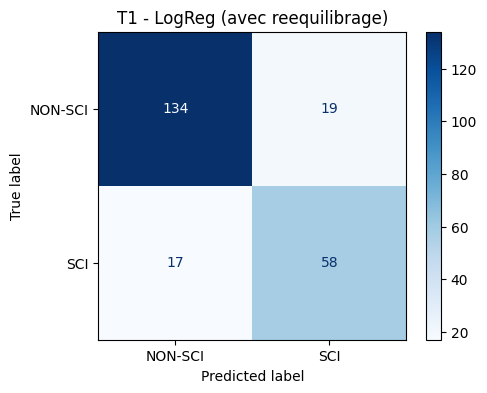

In [42]:
# Classification report
print('=== Classification report ===')
print(classification_report(y_test, y_pred, target_names=['NON-SCI', 'SCI']))

# Matrice de confusion
fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred),
                       display_labels=['NON-SCI', 'SCI']).plot(ax=ax, cmap='Blues')
ax.set_title('T1 - LogReg (avec reequilibrage)')
plt.show()

## Préparation des données finales (pour les 3 tâches)

**Démarche :** Le dataset SciTweets est nativement **multi-labels** : un tweet peut être simultanément CLAIM=1 et REF=1. La version précédente dérivait des labels par une règle de priorité (CLAIM > REF > CONTEXT), ce qui introduisait du bruit artificiel pour les tweets multi-étiquetés.

On utilise désormais :
- **T1** : inchangée — classification binaire SCI vs NON-SCI (1D)
- **T2** : matrice 2D `[CLAIM, REF]` —> un tweet peut être les deux à la fois
- **T3** : matrice 2D `[CLAIM, REF, CONTEXT]` —> un tweet peut avoir plusieurs étiquettes actives

Le classifieur **OneVsRestClassifier (OvR)** entraîne un binaire indépendant par colonne.

In [43]:
# Préparation commune : prétraitement complet

df_clean = main_pre_treatment_v2(
    df_original,
    use_numeric_features=True,
    use_special_tokens=True,
    filter_non_latin=True,
    keep_negations=True,
    use_lemmatization=True
)

NUMERIC_FEATURES = ['nb_links', 'nb_arobases', 'nb_hashtag',
                    'nb_emoji', 'has_question', 'has_exclamation', 'nb_uppercase']

# Tâche 1 : SCI vs NON-SCI (binaire, inchangée)
X_text_t1 = df_clean['text_lemmatized'].values
y_t1       = df_clean['science_related'].values  # vecteur 1D

print(f"T1 — Total : {len(y_t1)} | NON-SCI : {(y_t1==0).sum()} | SCI : {(y_t1==1).sum()}")

# Filtrage tweets SCI pour T2 et T3
df_sci = df_clean[df_clean['science_related'] == 1].copy().reset_index(drop=True)
print(f"\nTweets SCI retenus pour T2/T3 : {len(df_sci)}")
print(f"  CLAIM   : {df_sci['scientific_claim'].sum()}")
print(f"  REF     : {df_sci['scientific_reference'].sum()}")
print(f"  CONTEXT : {df_sci['scientific_context'].sum()}")

# Tweets effectivement multi-labels (plusieurs étiquettes actives)
multilabel_mask = (
    df_sci['scientific_claim'] + df_sci['scientific_reference'] + df_sci['scientific_context']
) > 1
print(f"\n  Tweets avec plusieurs labels simultanés : {multilabel_mask.sum()}")
print("  → Ces tweets justifient l'approche OvR : ils seraient mal représentés")
print("    par un label unique dérivé par règle de priorité.")

# Tâche 2 : multi-labels [CLAIM, REF]
# y_t2 est une matrice (n_samples, 2).
# OvR entraînera : un binaire "est-ce un CLAIM ?" et un binaire "est-ce un REF ?"
X_text_t2 = df_sci['text_lemmatized'].values
y_t2 = df_sci[['scientific_claim', 'scientific_reference']].values

print(f"\nT2 — Shape y_t2 : {y_t2.shape}")
print(f"  CLAIM seul        : {((y_t2[:,0]==1) & (y_t2[:,1]==0)).sum()}")
print(f"  REF seul          : {((y_t2[:,0]==0) & (y_t2[:,1]==1)).sum()}")
print(f"  CLAIM + REF       : {((y_t2[:,0]==1) & (y_t2[:,1]==1)).sum()}")
print(f"  Ni CLAIM ni REF   : {(y_t2.sum(axis=1)==0).sum()} (tweets CONTEXT purs)")

# Tâche 3 : multi-labels [CLAIM, REF, CONTEXT]
# y_t3 est une matrice (n_samples, 3).
X_text_t3 = df_sci['text_lemmatized'].values
y_t3 = df_sci[['scientific_claim', 'scientific_reference', 'scientific_context']].values

print(f"\nT3 — Shape y_t3 : {y_t3.shape}")
print(f"  CLAIM   actif : {y_t3[:,0].sum()}")
print(f"  REF     actif : {y_t3[:,1].sum()}")
print(f"  CONTEXT actif : {y_t3[:,2].sum()}")

T1 — Total : 1140 | NON-SCI : 765 | SCI : 375

Tweets SCI retenus pour T2/T3 : 375
  CLAIM   : 263.0
  REF     : 203.0
  CONTEXT : 251.0

  Tweets avec plusieurs labels simultanés : 218
  → Ces tweets justifient l'approche OvR : ils seraient mal représentés
    par un label unique dérivé par règle de priorité.

T2 — Shape y_t2 : (375, 2)
  CLAIM seul        : 139
  REF seul          : 79
  CLAIM + REF       : 124
  Ni CLAIM ni REF   : 33 (tweets CONTEXT purs)

T3 — Shape y_t3 : (375, 3)
  CLAIM   actif : 263.0
  REF     actif : 203.0
  CONTEXT actif : 251.0


## Fonction de cross-validation avec support multi-labels (OvR)

**Démarche :** La fonction `cross_val_evaluate` est adaptée pour gérer les deux cas :

- **`multilabel=False`** (T1) : tâche binaire classique avec SMOTE sur le fold train
- **`multilabel=True`** (T2, T3) : OvR encapsule chaque modèle de base. SMOTE est retiré
  car il ne supporte pas les matrices de labels 2D — le déséquilibre est géré par
  `class_weight='balanced'` dans chaque classifieur binaire du OvR.

**Métriques multi-labels :**
- `macro_f1` : même poids à chaque label (pénalise les labels rares non détectés)
- `samples_f1` : moyenne par instance (mesure la qualité globale par tweet)

In [44]:
def cross_val_evaluate(X_text, y, task_name, multilabel=False):
    """
    Cross-validation stratifiée 5 folds sans data leakage.

    Paramètres
    ----------
    multilabel : bool
        False → tâche binaire (T1), SMOTE activé, métriques binaires
        True  → tâche multi-labels (T2, T3), OvR activé, pas de SMOTE,
                métriques macro + samples

    Retourne
    --------
    summary : DataFrame  (moyenne ± std par modèle sur 5 folds)
    raw     : DataFrame  (métriques fold par fold)
    """
    base_models = {
        'ComplementNB': ComplementNB(),
        'LogReg':       LogisticRegression(max_iter=2000, class_weight='balanced',
                                           random_state=RANDOM_STATE),
        'LinearSVC':    LinearSVC(class_weight='balanced', random_state=RANDOM_STATE,
                                  max_iter=5000),
        'RandomForest': RandomForestClassifier(n_estimators=300, class_weight='balanced',
                                               random_state=RANDOM_STATE, n_jobs=-1),
        'KNN':          KNeighborsClassifier(n_neighbors=7),
    }

    raw_results = []

    # Stratification : en multi-labels on stratifie sur la colonne CLAIM (col 0),
    # la plus représentée, pour garantir sa présence dans chaque fold.
    y_strat = y if not multilabel else y[:, 0]

    for fold_idx, (train_idx, test_idx) in enumerate(CV.split(X_text, y_strat)):
        X_tr_raw, X_te_raw = X_text[train_idx], X_text[test_idx]
        y_tr = y[train_idx]
        y_te = y[test_idx]

        # TF-IDF fitté sur le fold train uniquement (pas de data leakage)
        tfidf_fold = TfidfVectorizer(max_features=5000, ngram_range=(1, 2),
                                     sublinear_tf=True, min_df=2, max_df=0.95)
        X_tr = tfidf_fold.fit_transform(X_tr_raw)
        X_te = tfidf_fold.transform(X_te_raw)

        # SMOTE uniquement pour T1 (binaire).
        # Pour T2/T3 : SMOTE ne supporte pas les matrices de labels 2D.
        # Le déséquilibre est géré par class_weight='balanced' dans chaque
        # classifieur binaire interne au OvR.
        if not multilabel:
            smote = SMOTE(random_state=RANDOM_STATE)
            X_tr, y_tr = smote.fit_resample(X_tr, y_tr)

        for name, base_model in base_models.items():
            m = clone(base_model)

            # OvR encapsule le classifieur de base pour le multi-labels.
            # Pour le binaire (T1), on utilise directement le classifieur.
            if multilabel:
                model = OneVsRestClassifier(m, n_jobs=-1)
            else:
                model = m

            model.fit(X_tr, y_tr)
            y_pred = model.predict(X_te)

            avg = 'binary' if not multilabel else 'macro'

            row = {
                'task':      task_name,
                'model':     name,
                'fold':      fold_idx + 1,
                'accuracy':  accuracy_score(y_te, y_pred),
                'precision': precision_score(y_te, y_pred, average=avg, zero_division=0),
                'recall':    recall_score(y_te, y_pred, average=avg, zero_division=0),
                'f1':        f1_score(y_te, y_pred, average=avg, zero_division=0),
                'macro_f1':  f1_score(y_te, y_pred, average='macro', zero_division=0),
                'samples_f1': (f1_score(y_te, y_pred, average='samples', zero_division=0)
                               if multilabel else None),
            }
            raw_results.append(row)

    raw = pd.DataFrame(raw_results)

    agg_cols = ['accuracy', 'precision', 'recall', 'f1', 'macro_f1']
    if multilabel:
        agg_cols.append('samples_f1')

    summary = (
        raw.groupby('model')[agg_cols]
        .agg(['mean', 'std'])
        .round(3)
    )
    summary.columns = ['_'.join(c) for c in summary.columns]
    summary.insert(0, 'task', task_name)

    return summary, raw

## Lancement de la cross-validation sur les 3 tâches

**Paramètre `multilabel` :**
- T1 : `False` — binaire classique avec SMOTE
- T2 : `True` — OvR sur 2 labels [CLAIM, REF]
- T3 : `True` — OvR sur 3 labels [CLAIM, REF, CONTEXT]

In [45]:

print(" Tâche 1 : SCI vs NON-SCI (binaire)")

summary_t1, raw_t1 = cross_val_evaluate(
    X_text_t1, y_t1,
    task_name='T1_SCI_vs_NONSCI',
    multilabel=False
)
print(summary_t1[['task','macro_f1_mean','macro_f1_std','accuracy_mean','precision_mean','recall_mean']])


print(" Tâche 2 : CLAIM et/ou REF (multi-labels OvR)")

summary_t2, raw_t2 = cross_val_evaluate(
    X_text_t2, y_t2,
    task_name='T2_CLAIM_REF_multilabel',
    multilabel=True
)
print(summary_t2[['task','macro_f1_mean','macro_f1_std','samples_f1_mean','accuracy_mean']])


print(" Tâche 3 : CLAIM / REF / CONTEXT (multi-labels OvR)")

summary_t3, raw_t3 = cross_val_evaluate(
    X_text_t3, y_t3,
    task_name='T3_CLAIM_REF_CONTEXT_multilabel',
    multilabel=True
)
print(summary_t3[['task','macro_f1_mean','macro_f1_std','samples_f1_mean','accuracy_mean']])

 Tâche 1 : SCI vs NON-SCI (binaire)
                          task  macro_f1_mean  macro_f1_std  accuracy_mean  \
model                                                                        
ComplementNB  T1_SCI_vs_NONSCI          0.765         0.026          0.782   
KNN           T1_SCI_vs_NONSCI          0.334         0.016          0.382   
LinearSVC     T1_SCI_vs_NONSCI          0.785         0.026          0.809   
LogReg        T1_SCI_vs_NONSCI          0.794         0.020          0.813   
RandomForest  T1_SCI_vs_NONSCI          0.778         0.016          0.814   

              precision_mean  recall_mean  
model                                      
ComplementNB           0.641        0.771  
KNN                    0.346        0.989  
LinearSVC              0.705        0.728  
LogReg                 0.695        0.771  
RandomForest           0.767        0.624  
 Tâche 2 : CLAIM et/ou REF (multi-labels OvR)
                                 task  macro_f1_mean  macro_f1_

## Optimisation des hyperparamètres par GridSearchCV (OvR)

**Démarche :** Le GridSearch est adapté pour le multi-labels :
- Pour T2/T3 : `OneVsRestClassifier` encapsule le classifieur dans le pipeline.
  Les hyperparamètres internes sont accessibles via le préfixe `clf__estimator__`
  (convention sklearn pour les meta-estimateurs).
- SMOTE est retiré du pipeline pour T2/T3 (non compatible multi-labels).
- Pour T1 : pipeline inchangé avec SMOTE.

In [46]:
def make_grid_pipeline_ovr(model_name, multilabel=False):
    """
    Construit un ImbPipeline adapté au mode binaire ou multi-labels.

    - binaire (T1)     : TF-IDF → SMOTE → classifieur
    - multi-labels (T2,T3) : TF-IDF → OvR(classifieur)  [pas de SMOTE]

    Note sur les préfixes de paramètres :
      - Binaire    : 'clf__C', 'clf__class_weight', ...
      - Multi-labels : 'clf__estimator__C', 'clf__estimator__class_weight', ...
        car OvR est le clf, et le classifieur de base est son estimator interne.
    """
    if multilabel:
        models_and_grids = {
            'LogReg': (
                LogisticRegression(max_iter=2000, random_state=RANDOM_STATE),
                {
                    'clf__estimator__C':            [0.01, 0.1, 1, 10, 100],
                    'clf__estimator__class_weight': [None, 'balanced'],
                    'clf__estimator__solver':       ['lbfgs', 'liblinear'],
                }
            ),
            'LinearSVC': (
                LinearSVC(max_iter=5000, random_state=RANDOM_STATE),
                {
                    'clf__estimator__C':            [0.01, 0.1, 1, 10, 100],
                    'clf__estimator__class_weight': [None, 'balanced'],
                }
            ),
            'RandomForest': (
                RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1),
                {
                    'clf__estimator__n_estimators':  [100, 300],
                    'clf__estimator__max_depth':     [None, 10, 30],
                    'clf__estimator__class_weight':  [None, 'balanced'],
                }
            ),
            'ComplementNB': (
                ComplementNB(),
                {'clf__estimator__alpha': [0.01, 0.1, 0.5, 1.0, 2.0]}
            ),
            'KNN': (
                KNeighborsClassifier(),
                {
                    'clf__estimator__n_neighbors': [3, 5, 7, 11, 15],
                    'clf__estimator__metric':      ['euclidean', 'cosine'],
                }
            ),
        }
    else:
        models_and_grids = {
            'LogReg': (
                LogisticRegression(max_iter=2000, random_state=RANDOM_STATE),
                {
                    'clf__C':            [0.01, 0.1, 1, 10, 100],
                    'clf__class_weight': [None, 'balanced'],
                    'clf__solver':       ['lbfgs', 'liblinear'],
                }
            ),
            'LinearSVC': (
                LinearSVC(max_iter=5000, random_state=RANDOM_STATE),
                {
                    'clf__C':            [0.01, 0.1, 1, 10, 100],
                    'clf__class_weight': [None, 'balanced'],
                }
            ),
            'RandomForest': (
                RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1),
                {
                    'clf__n_estimators':  [100, 300, 500],
                    'clf__max_depth':     [None, 10, 30],
                    'clf__class_weight':  [None, 'balanced'],
                }
            ),
            'ComplementNB': (
                ComplementNB(),
                {'clf__alpha': [0.01, 0.1, 0.5, 1.0, 2.0]}
            ),
            'KNN': (
                KNeighborsClassifier(),
                {
                    'clf__n_neighbors': [3, 5, 7, 11, 15],
                    'clf__metric':      ['euclidean', 'cosine'],
                }
            ),
        }

    base_clf, param_grid = models_and_grids[model_name]

    if multilabel:
        clf = OneVsRestClassifier(base_clf, n_jobs=-1)
        pipeline = ImbPipeline([
            ('tfidf', TfidfVectorizer(max_features=5000, ngram_range=(1, 2),
                                      sublinear_tf=True, min_df=2, max_df=0.95)),
            ('clf',   clf),
        ])
    else:
        pipeline = ImbPipeline([
            ('tfidf',  TfidfVectorizer(max_features=5000, ngram_range=(1, 2),
                                       sublinear_tf=True, min_df=2, max_df=0.95)),
            ('smote',  SMOTE(random_state=RANDOM_STATE)),
            ('clf',    base_clf),
        ])

    return pipeline, param_grid


def run_grid_search_ovr(X_text, y, model_name, task_name, multilabel=False):
    """
    Lance GridSearchCV sur le pipeline adapté (binaire ou OvR multi-labels).

    Problème connu : StratifiedKFold (utilisé dans CV global) ne supporte pas
    les matrices de labels 2D (multilabel-indicator).
    Solution : on pré-calcule les indices de folds en stratifiant sur y[:,0]
    (colonne CLAIM, la plus représentée), puis on passe ces indices directement
    à GridSearchCV via le paramètre cv — ce qui court-circuite la stratification
    automatique de sklearn.
    """
    pipeline, param_grid = make_grid_pipeline_ovr(model_name, multilabel)

    # Split 80/20 — stratification sur col 0 pour le multi-labels
    y_strat = y if not multilabel else y[:, 0]
    X_tr, X_te, y_tr, y_te = train_test_split(
        X_text, y, test_size=0.2, stratify=y_strat, random_state=RANDOM_STATE
    )

    # Pour le multi-labels : pré-calcul des folds pour éviter le bug StratifiedKFold
    # On stratifie sur y_tr[:,0] (CLAIM) et on passe les indices directement à GridSearchCV
    if multilabel:
        cv_splitter = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
        cv_indices = list(cv_splitter.split(X_tr, y_tr[:, 0]))
    else:
        cv_indices = CV

    grid = GridSearchCV(
        pipeline, param_grid,
        scoring='f1_macro',
        cv=cv_indices,
        n_jobs=-1, verbose=1, refit=True
    )


    print(f"GridSearch OvR — {task_name} — {model_name}")

    grid.fit(X_tr, y_tr)

    print(f"Meilleurs paramètres : {grid.best_params_}")
    print(f"Meilleur score CV (macro F1) : {grid.best_score_:.4f}")

    y_pred = grid.predict(X_te)
    print(f"\n-   Évaluation sur le test set   -")
    if multilabel:
        label_map = {2: ['CLAIM', 'REF'], 3: ['CLAIM', 'REF', 'CONTEXT']}
        label_names = label_map.get(y.shape[1])
        print(classification_report(y_te, y_pred, target_names=label_names, zero_division=0))
    else:
        print(classification_report(y_te, y_pred, zero_division=0))

    return grid, X_te, y_te

# Identification des meilleurs modèles
best_t1 = summary_t1['macro_f1_mean'].idxmax()
best_t2 = summary_t2['macro_f1_mean'].idxmax()
best_t3 = summary_t3['macro_f1_mean'].idxmax()

print(f"Modèle retenu T1 : {best_t1}")
print(f"Modèle retenu T2 : {best_t2}")
print(f"Modèle retenu T3 : {best_t3}")

# Lancement
grid_t1, X_te_t1, y_te_t1 = run_grid_search_ovr(
    X_text_t1, y_t1, best_t1, 'T1_SCI_vs_NONSCI', multilabel=False
)
grid_t2, X_te_t2, y_te_t2 = run_grid_search_ovr(
    X_text_t2, y_t2, best_t2, 'T2_CLAIM_REF_multilabel', multilabel=True
)
grid_t3, X_te_t3, y_te_t3 = run_grid_search_ovr(
    X_text_t3, y_t3, best_t3, 'T3_CLAIM_REF_CONTEXT_multilabel', multilabel=True
)

Modèle retenu T1 : LogReg
Modèle retenu T2 : RandomForest
Modèle retenu T3 : RandomForest
GridSearch OvR — T1_SCI_vs_NONSCI — LogReg
Fitting 5 folds for each of 20 candidates, totalling 100 fits
Meilleurs paramètres : {'clf__C': 1, 'clf__class_weight': None, 'clf__solver': 'liblinear'}
Meilleur score CV (macro F1) : 0.7806

-   Évaluation sur le test set   -
              precision    recall  f1-score   support

           0       0.86      0.88      0.87       153
           1       0.74      0.72      0.73        75

    accuracy                           0.82       228
   macro avg       0.80      0.80      0.80       228
weighted avg       0.82      0.82      0.82       228

GridSearch OvR — T2_CLAIM_REF_multilabel — RandomForest
Fitting 5 folds for each of 12 candidates, totalling 60 fits
Meilleurs paramètres : {'clf__estimator__class_weight': None, 'clf__estimator__max_depth': 30, 'clf__estimator__n_estimators': 100}
Meilleur score CV (macro F1) : 0.8281

-   Évaluation sur le te

##Visualisation comparative
Démarche :
On produit deux types de visualisations. Graphiques en barres horizontales avec barres d'erreur (écart-type inter-folds) pour comparer les modèles sur chaque tâche.

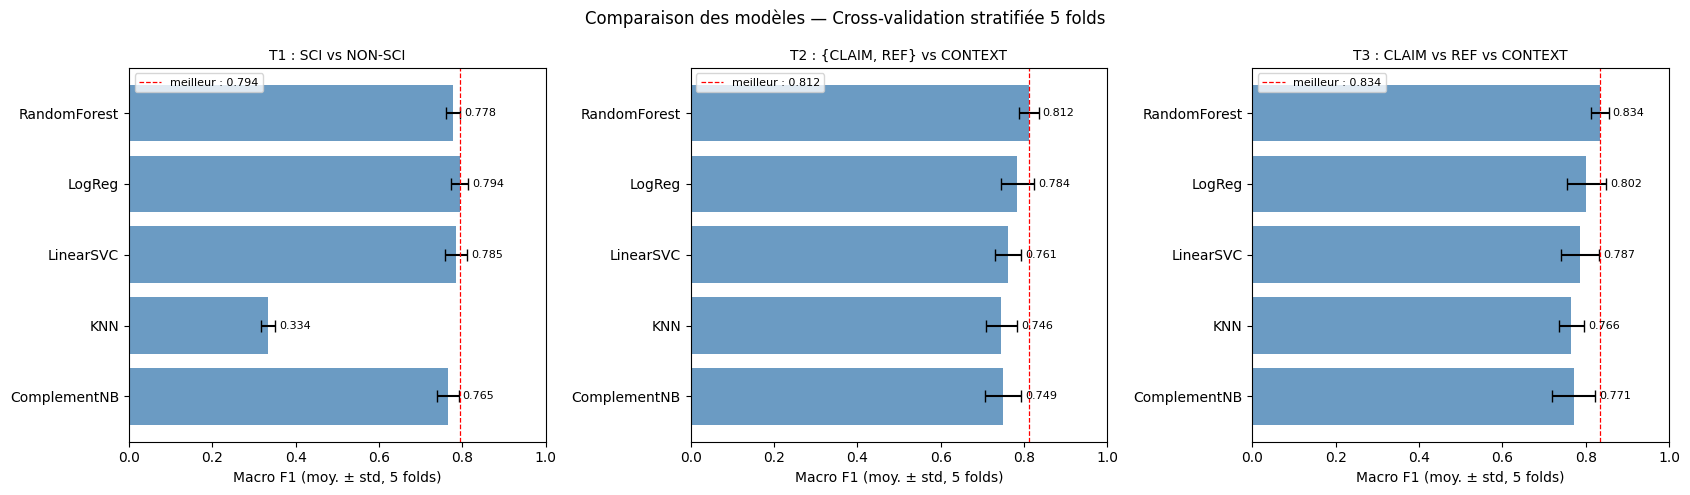


  Tableau comparatif global 
                                         task  accuracy_mean  accuracy_std  precision_mean  recall_mean  macro_f1_mean  macro_f1_std
model                                                                                                                               
ComplementNB                 T1_SCI_vs_NONSCI          0.782         0.023           0.641        0.771          0.765         0.026
KNN                          T1_SCI_vs_NONSCI          0.382         0.010           0.346        0.989          0.334         0.016
LinearSVC                    T1_SCI_vs_NONSCI          0.809         0.026           0.705        0.728          0.785         0.026
LogReg                       T1_SCI_vs_NONSCI          0.813         0.017           0.695        0.771          0.794         0.020
RandomForest                 T1_SCI_vs_NONSCI          0.814         0.013           0.767        0.624          0.778         0.016
ComplementNB          T2_CLAIM_REF_mult

In [47]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

tasks_viz = [
    ('T1 : SCI vs NON-SCI',          summary_t1),
    ('T2 : {CLAIM, REF} vs CONTEXT', summary_t2),
    ('T3 : CLAIM vs REF vs CONTEXT', summary_t3),
]

for ax, (title, summary) in zip(axes, tasks_viz):
    means = summary['macro_f1_mean']
    stds  = summary['macro_f1_std']
    mdls  = summary.index

    ax.barh(mdls, means, xerr=stds, capsize=4,
            color='steelblue', alpha=0.8, ecolor='black')
    ax.axvline(means.max(), color='red', linestyle='--',
               linewidth=0.9, label=f'meilleur : {means.max():.3f}')
    ax.set_xlim(0, 1)
    ax.set_xlabel('Macro F1 (moy. ± std, 5 folds)')
    ax.set_title(title, fontsize=10)
    ax.legend(fontsize=8)

    for i, (m, s) in enumerate(zip(means, stds)):
        ax.text(min(m + s + 0.01, 0.97), i, f'{m:.3f}', va='center', fontsize=8)

plt.suptitle('Comparaison des modèles — Cross-validation stratifiée 5 folds', fontsize=12)
plt.tight_layout()
plt.show()

all_summaries = pd.concat([summary_t1, summary_t2, summary_t3])
cols_rapport  = ['task', 'accuracy_mean', 'accuracy_std',
                 'precision_mean', 'recall_mean', 'macro_f1_mean', 'macro_f1_std']
print("\n  Tableau comparatif global ")
print(all_summaries[cols_rapport].to_string())

## Matrices de confusion (meilleur modèle par tâche)

**Démarche :** Pour T1 (binaire) : matrice de confusion standard.
Pour T2 et T3 (multi-labels OvR) : une matrice par label (une par classifieur binaire interne),
ce qui permet d'analyser les erreurs label par label.


 T1 — LogReg 
              precision    recall  f1-score   support

     NON-SCI       0.86      0.88      0.87       153
         SCI       0.74      0.72      0.73        75

    accuracy                           0.82       228
   macro avg       0.80      0.80      0.80       228
weighted avg       0.82      0.82      0.82       228



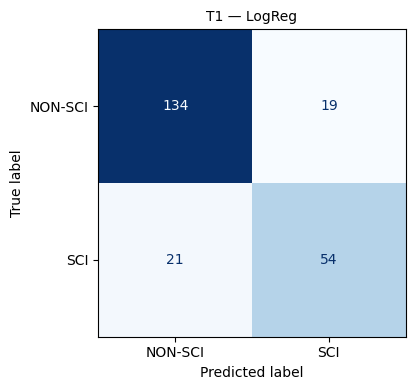


 T2 — RandomForest (OvR) 
              precision    recall  f1-score   support

       CLAIM       0.81      0.91      0.86        53
         REF       0.61      0.86      0.71        35

   micro avg       0.72      0.89      0.80        88
   macro avg       0.71      0.88      0.79        88
weighted avg       0.73      0.89      0.80        88
 samples avg       0.74      0.77      0.73        88



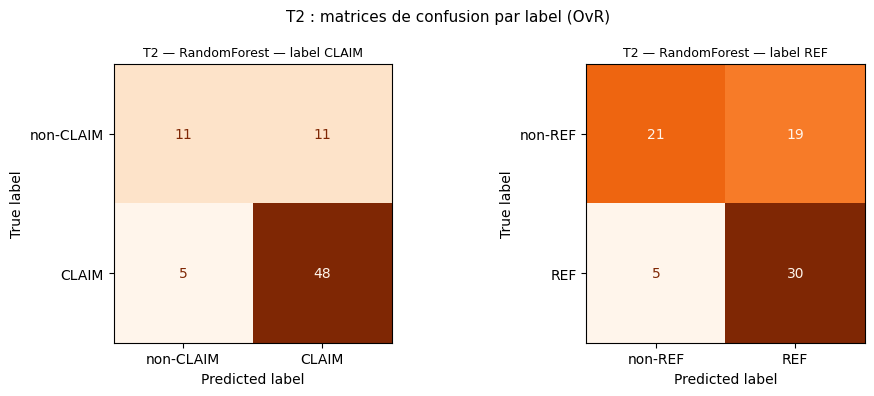


 T3 — RandomForest (OvR) 
              precision    recall  f1-score   support

       CLAIM       0.81      0.91      0.86        53
         REF       0.61      0.86      0.71        35
     CONTEXT       0.81      0.94      0.87        50

   micro avg       0.75      0.91      0.82       138
   macro avg       0.75      0.90      0.81       138
weighted avg       0.76      0.91      0.83       138
 samples avg       0.78      0.91      0.80       138



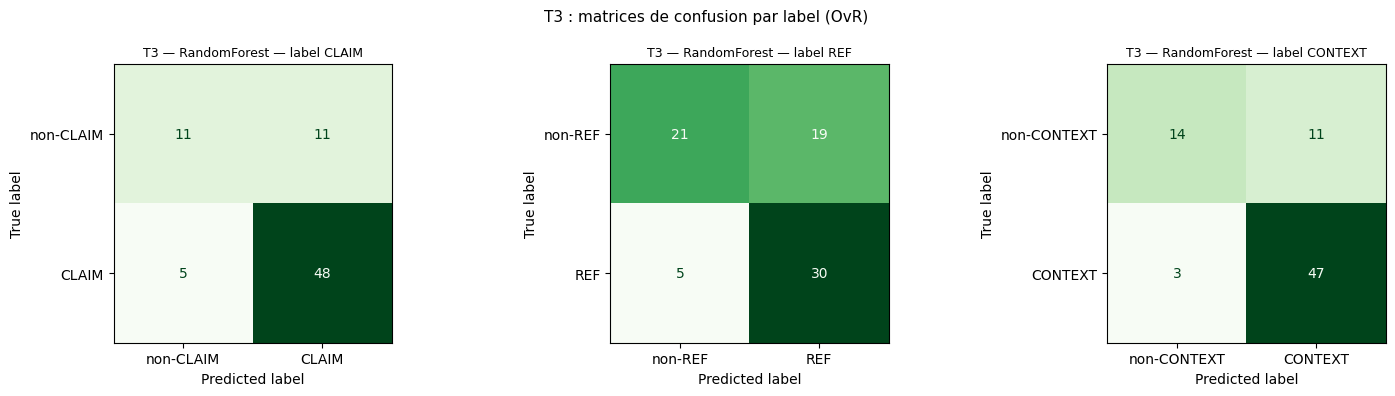

In [48]:
def confusion_best_model_binary(X_text, y, best_model_name, task_name, label_names):
    """Matrice de confusion pour T1 (tâche binaire)."""
    models_ref = {
        'ComplementNB': ComplementNB(),
        'LogReg':       LogisticRegression(max_iter=2000, class_weight='balanced',
                                           random_state=RANDOM_STATE),
        'LinearSVC':    LinearSVC(class_weight='balanced', random_state=RANDOM_STATE,
                                  max_iter=5000),
        'RandomForest': RandomForestClassifier(n_estimators=300, class_weight='balanced',
                                               random_state=RANDOM_STATE, n_jobs=-1),
        'KNN':          KNeighborsClassifier(n_neighbors=7),
    }
    model = clone(models_ref[best_model_name])

    X_tr, X_te, y_tr, y_te = train_test_split(
        X_text, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
    )
    tfidf_cm = TfidfVectorizer(max_features=5000, ngram_range=(1,2),
                                sublinear_tf=True, min_df=2, max_df=0.95)
    X_tr_v = tfidf_cm.fit_transform(X_tr)
    X_te_v = tfidf_cm.transform(X_te)

    smote = SMOTE(random_state=RANDOM_STATE)
    X_tr_b, y_tr_b = smote.fit_resample(X_tr_v, y_tr)

    model.fit(X_tr_b, y_tr_b)
    y_pred = model.predict(X_te_v)

    print(f"\n {task_name} — {best_model_name} ")
    print(classification_report(y_te, y_pred, target_names=label_names, zero_division=0))
    return confusion_matrix(y_te, y_pred), label_names, task_name, best_model_name


def confusion_best_model_multilabel(X_text, y, best_model_name, task_name, label_names):
    """
    Matrices de confusion pour T2/T3 (multi-labels OvR).
    OvR entraîne un binaire par label → une matrice de confusion par label.
    """
    models_ref = {
        'ComplementNB': ComplementNB(),
        'LogReg':       LogisticRegression(max_iter=2000, class_weight='balanced',
                                           random_state=RANDOM_STATE),
        'LinearSVC':    LinearSVC(class_weight='balanced', random_state=RANDOM_STATE,
                                  max_iter=5000),
        'RandomForest': RandomForestClassifier(n_estimators=300, class_weight='balanced',
                                               random_state=RANDOM_STATE, n_jobs=-1),
        'KNN':          KNeighborsClassifier(n_neighbors=7),
    }
    base_model = clone(models_ref[best_model_name])
    model = OneVsRestClassifier(base_model, n_jobs=-1)

    y_strat = y[:, 0]
    X_tr, X_te, y_tr, y_te = train_test_split(
        X_text, y, test_size=0.2, stratify=y_strat, random_state=RANDOM_STATE
    )
    tfidf_cm = TfidfVectorizer(max_features=5000, ngram_range=(1,2),
                                sublinear_tf=True, min_df=2, max_df=0.95)
    X_tr_v = tfidf_cm.fit_transform(X_tr)
    X_te_v = tfidf_cm.transform(X_te)

    model.fit(X_tr_v, y_tr)
    y_pred = model.predict(X_te_v)

    print(f"\n {task_name} — {best_model_name} (OvR) ")
    print(classification_report(y_te, y_pred, target_names=label_names, zero_division=0))

    # Une matrice par label
    cms = []
    for i, lbl in enumerate(label_names):
        cms.append((confusion_matrix(y_te[:, i], y_pred[:, i]), lbl))
    return cms, task_name, best_model_name


# T1 : matrice binaire
best_t1 = summary_t1['macro_f1_mean'].idxmax()
best_t2 = summary_t2['macro_f1_mean'].idxmax()
best_t3 = summary_t3['macro_f1_mean'].idxmax()

cm1, ln1, tn1, mn1 = confusion_best_model_binary(
    X_text_t1, y_t1, best_t1, 'T1', ['NON-SCI', 'SCI']
)

fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay(cm1, display_labels=ln1).plot(ax=ax, cmap='Blues', colorbar=False)
ax.set_title(f"T1 — {mn1}", fontsize=10)
plt.tight_layout()
plt.show()

# T2 : matrices par label (CLAIM, REF)
cms2, tn2, mn2 = confusion_best_model_multilabel(
    X_text_t2, y_t2, best_t2, 'T2', ['CLAIM', 'REF']
)
fig, axes = plt.subplots(1, len(cms2), figsize=(5*len(cms2), 4))
if len(cms2) == 1:
    axes = [axes]
for ax, (cm, lbl) in zip(axes, cms2):
    ConfusionMatrixDisplay(cm, display_labels=[f'non-{lbl}', lbl]).plot(
        ax=ax, cmap='Oranges', colorbar=False)
    ax.set_title(f"T2 — {mn2} — label {lbl}", fontsize=9)
plt.suptitle('T2 : matrices de confusion par label (OvR)', fontsize=11)
plt.tight_layout()
plt.show()

# T3 : matrices par label (CLAIM, REF, CONTEXT)
cms3, tn3, mn3 = confusion_best_model_multilabel(
    X_text_t3, y_t3, best_t3, 'T3', ['CLAIM', 'REF', 'CONTEXT']
)
fig, axes = plt.subplots(1, len(cms3), figsize=(5*len(cms3), 4))
for ax, (cm, lbl) in zip(axes, cms3):
    ConfusionMatrixDisplay(cm, display_labels=[f'non-{lbl}', lbl]).plot(
        ax=ax, cmap='Greens', colorbar=False)
    ax.set_title(f"T3 — {mn3} — label {lbl}", fontsize=9)
plt.suptitle('T3 : matrices de confusion par label (OvR)', fontsize=11)
plt.tight_layout()
plt.show()

## BONUS — Features discriminantes

**Démarche :** Pour T2 et T3 (OvR), chaque classifieur binaire interne possède ses propres
coefficients. On accède aux coefficients via `model.estimators_[i].coef_` pour le i-ème
label. Cela permet d'identifier les mots les plus discriminants **par label**, ce qui est
plus riche qu'une analyse globale.

In [49]:
def top_features_binary(model, tfidf_vectorizer, class_names, top_n=15):
    """Features discriminantes pour un classifieur binaire (T1)."""
    if not hasattr(model, 'coef_'):
        print(f"  {type(model).__name__} : pas de coef_ disponible.")
        return
    feature_names = np.array(tfidf_vectorizer.get_feature_names_out())
    coefs = model.coef_
    if coefs.shape[0] == 1:
        coefs = np.vstack([-coefs[0], coefs[0]])
    for i, cls in enumerate(class_names):
        top_idx = np.argsort(coefs[i])[-top_n:][::-1]
        print(f"  Top {top_n} pour [{cls}] :")
        for idx in top_idx:
            print(f"    {feature_names[idx]:<30}  coef = {coefs[i][idx]:.4f}")
        print()


def top_features_ovr(ovr_model, tfidf_vectorizer, label_names, top_n=15):
    """
    Features discriminantes pour un OvR (T2, T3).
    OvR stocke ses classifieurs binaires dans ovr_model.estimators_[i].
    On extrait les coefs de chaque estimateur interne.
    """
    feature_names = np.array(tfidf_vectorizer.get_feature_names_out())
    for i, (estimator, label) in enumerate(zip(ovr_model.estimators_, label_names)):
        if not hasattr(estimator, 'coef_'):
            print(f"  [{label}] : {type(estimator).__name__} sans coef_")
            continue
        coefs = estimator.coef_.ravel()
        top_idx = np.argsort(coefs)[-top_n:][::-1]
        bot_idx = np.argsort(coefs)[:top_n]
        print(f"  Top {top_n} mots pour [présence de {label}] :")
        for idx in top_idx:
            print(f"    {feature_names[idx]:<30}  coef = {coefs[idx]:.4f}")
        print(f"  Top {top_n} mots contre [présence de {label}] :")
        for idx in bot_idx:
            print(f"    {feature_names[idx]:<30}  coef = {coefs[idx]:.4f}")
        print()


def fit_for_features_binary(X_text, y, model):
    """Fit TF-IDF + modèle binaire sur 100% des données."""
    tfidf_full = TfidfVectorizer(max_features=5000, ngram_range=(1,2),
                                  sublinear_tf=True, min_df=2, max_df=0.95)
    X_full = tfidf_full.fit_transform(X_text)
    smote = SMOTE(random_state=RANDOM_STATE)
    X_b, y_b = smote.fit_resample(X_full, y)
    model.fit(X_b, y_b)
    return model, tfidf_full


def fit_for_features_ovr(X_text, y, base_model):
    """Fit TF-IDF + OvR sur 100% des données."""
    tfidf_full = TfidfVectorizer(max_features=5000, ngram_range=(1,2),
                                  sublinear_tf=True, min_df=2, max_df=0.95)
    X_full = tfidf_full.fit_transform(X_text)
    ovr = OneVsRestClassifier(base_model, n_jobs=-1)
    ovr.fit(X_full, y)
    return ovr, tfidf_full


# T1 : features binaires

print("BONUS — T1 : Features discriminantes (LogReg binaire)")

logreg_t1, tfidf_feat_t1 = fit_for_features_binary(
    X_text_t1, y_t1,
    LogisticRegression(max_iter=2000, class_weight='balanced', random_state=RANDOM_STATE)
)
top_features_binary(logreg_t1, tfidf_feat_t1, ['NON-SCI', 'SCI'])

# T2 : features OvR [CLAIM, REF]

print("BONUS — T2 : Features discriminantes (OvR LinearSVC — labels CLAIM, REF)")

ovr_t2, tfidf_feat_t2 = fit_for_features_ovr(
    X_text_t2, y_t2,
    LinearSVC(class_weight='balanced', random_state=RANDOM_STATE, max_iter=5000)
)
top_features_ovr(ovr_t2, tfidf_feat_t2, ['CLAIM', 'REF'])

# T3 : features OvR [CLAIM, REF, CONTEXT]

print("BONUS — T3 : Features discriminantes (OvR LinearSVC — labels CLAIM, REF, CONTEXT)")

ovr_t3, tfidf_feat_t3 = fit_for_features_ovr(
    X_text_t3, y_t3,
    LinearSVC(class_weight='balanced', random_state=RANDOM_STATE, max_iter=5000)
)
top_features_ovr(ovr_t3, tfidf_feat_t3, ['CLAIM', 'REF', 'CONTEXT'])

BONUS — T1 : Features discriminantes (LogReg binaire)
  Top 15 pour [NON-SCI] :
    stop                            coef = 4.5844
    support                         coef = 3.8342
    report                          coef = 2.1407
    need                            coef = 1.5114
    treat                           coef = 1.3761
    promote                         coef = 1.2952
    usertoken                       coef = 1.2847
    get                             coef = 1.1865
    trump                           coef = 1.1150
    please                          coef = 1.0892
    news                            coef = 1.0233
    engineer                        coef = 0.9605
    numtoken                        coef = 0.9335
    thing                           coef = 0.9286
    lower                           coef = 0.8928

  Top 15 pour [SCI] :
    urltoken                        coef = 3.5394
    health                          coef = 2.6293
    research                        coef = 2.53

#Conclusion
L'approche One-vs-Rest multi-labels constitue une avancée significative par rapport à la modélisation mono-label sur les tâches T2 et T3. La dérivation d'un label unique par règle de priorité (CLAIM > REF > CONTEXT) introduisait un biais artificiel sur les 124 tweets portant simultanément les labels CLAIM et REF, forçant une appartenance exclusive là où le problème est nativement multi-labels. L'OvR lève cette contrainte en entraînant un classifieur binaire indépendant par label, ce qui respecte la structure réelle des annotations.
Les gains en résultats sont substantiels. Sur T2, le macro F1 passe de 0,680 (meilleur modèle mono-label, LogReg) à 0,812 (RandomForest OvR), soit un gain de 13 points. Sur T3, il passe de 0,577 à 0,834, soit un gain de 26 points. Le rappel s'améliore de façon particulièrement marquée : de 0,586 à 0,916 sur T3  traduisant la capacité du modèle OvR à détecter les labels actifs sans être pénalisé par les tweets multi-labellisés. La précision progresse également, de 0,586 à 0,771 sur T3. L'accuracy, structurellement plus sévère en multi-labels car elle exige la correction simultanée de tous les labels, reste autour de 0,50 mais c'est un critère moins déterminant ici.
Ces résultats valident ainsi la pertinence de l'approche multi-label comme modélisation pour ce problème.

## Export des résultats

In [50]:
import json

def serialize(obj):
    """Convertit les types numpy/pandas en types Python natifs pour JSON."""
    if isinstance(obj, (np.integer,)):  return int(obj)
    if isinstance(obj, (np.floating,)): return float(obj)
    if isinstance(obj, np.ndarray):     return obj.tolist()
    return str(obj)

def export_grid_results(grid, X_te, y_te, label_names, multilabel=False):
    try:
        y_pred = grid.predict(X_te)
        return {
            "best_params":           grid.best_params_,
            "best_cv_score":         float(grid.best_score_),
            "test_f1_macro":         float(f1_score(y_te, y_pred, average='macro', zero_division=0)),
            "test_samples_f1":       (float(f1_score(y_te, y_pred, average='samples', zero_division=0))
                                      if multilabel else None),
            "classification_report": classification_report(
                y_te, y_pred,
                target_names=label_names,
                output_dict=True, zero_division=0
            ),
        }
    except Exception as e:
        return {"erreur": str(e)}

resultats = {
    "distributions": {
        "T1": {"NON-SCI": int((y_t1==0).sum()), "SCI": int((y_t1==1).sum())},
        "T2": {"CLAIM": int(y_t2[:,0].sum()), "REF": int(y_t2[:,1].sum()),
               "tweets_multilabel": int(((y_t2[:,0]==1) & (y_t2[:,1]==1)).sum())},
        "T3": {"CLAIM": int(y_t3[:,0].sum()), "REF": int(y_t3[:,1].sum()),
               "CONTEXT": int(y_t3[:,2].sum())},
    },
    "cross_validation": {},
    "grid_search": {},
}

for task_name, summary_var in [("T1","summary_t1"),("T2","summary_t2"),("T3","summary_t3")]:
    try:
        s = eval(summary_var)
        resultats["cross_validation"][task_name] = json.loads(
            s.reset_index().to_json(orient='records')
        )
    except Exception as e:
        resultats["cross_validation"][task_name] = {"erreur": str(e)}

grid_configs = {
    "T1": ("grid_t1", "X_te_t1", "y_te_t1", ["NON-SCI", "SCI"],           False),
    "T2": ("grid_t2", "X_te_t2", "y_te_t2", ["CLAIM", "REF"],             True),
    "T3": ("grid_t3", "X_te_t3", "y_te_t3", ["CLAIM", "REF", "CONTEXT"],  True),
}

for task_name, (g, X, y, labels, ml) in grid_configs.items():
    try:
        resultats["grid_search"][task_name] = export_grid_results(
            eval(g), eval(X), eval(y), labels, multilabel=ml
        )
    except NameError:
        resultats["grid_search"][task_name] = {"statut": "GridSearch non encore exécuté"}
    except Exception as e:
        resultats["grid_search"][task_name] = {"erreur": str(e)}

output_path = my_local_drive + '/resultats_ml.json'
with open(output_path, 'w') as f:
    json.dump(resultats, f, indent=2, default=serialize)

print(f"✓ Exporté : {output_path}")
print(f"  CV      : {list(resultats['cross_validation'].keys())}")
print(f"  Grid    : { {k: 'OK' if 'best_params' in v else v.get('statut', v.get('erreur','?')) for k, v in resultats['grid_search'].items()} }")

✓ Exporté : /content/drive/MyDrive/Projet ML1 Master ICo/resultats_ml.json
  CV      : ['T1', 'T2', 'T3']
  Grid    : {'T1': 'OK', 'T2': 'OK', 'T3': 'OK'}


In [51]:
#  Export de tous les graphiques en PNG

import matplotlib
matplotlib.use('Agg')

figures_dir = my_local_drive + '/figures'
import os
os.makedirs(figures_dir, exist_ok=True)

# 1. Comparaison CV : macro F1 par modèle
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
tasks_viz = [
    ('T1 : SCI vs NON-SCI',            summary_t1),
    ('T2 : CLAIM et/ou REF (OvR)',      summary_t2),
    ('T3 : CLAIM / REF / CONTEXT (OvR)',summary_t3),
]
for ax, (title, summary) in zip(axes, tasks_viz):
    means = summary['macro_f1_mean']
    stds  = summary['macro_f1_std']
    ax.barh(summary.index, means, xerr=stds, capsize=4,
            color='steelblue', alpha=0.8, ecolor='black')
    ax.axvline(means.max(), color='red', linestyle='--', linewidth=0.9,
               label=f'meilleur : {means.max():.3f}')
    ax.set_xlim(0, 1)
    ax.set_xlabel('Macro F1 (moy. ± std, 5 folds)')
    ax.set_title(title, fontsize=10)
    ax.legend(fontsize=8)
    for i, (m, s) in enumerate(zip(means, stds)):
        ax.text(min(m + s + 0.01, 0.97), i, f'{m:.3f}', va='center', fontsize=8)
plt.suptitle('Comparaison des modèles — Cross-validation stratifiée 5 folds', fontsize=12)
plt.tight_layout()
plt.savefig(figures_dir + '/cv_comparaison.png', dpi=150, bbox_inches='tight')
plt.show()
print("✓ cv_comparaison.png")

# 2. Matrice de confusion T1
fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay(cm1, display_labels=ln1).plot(ax=ax, cmap='Blues', colorbar=False)
ax.set_title(f"T1 — {mn1}")
plt.tight_layout()
plt.savefig(figures_dir + '/confusion_t1.png', dpi=150, bbox_inches='tight')
plt.show()
print("✓ confusion_t1.png")

# 3. Matrices de confusion T2 (une par label)
fig, axes = plt.subplots(1, len(cms2), figsize=(5*len(cms2), 4))
if len(cms2) == 1: axes = [axes]
for ax, (cm, lbl) in zip(axes, cms2):
    ConfusionMatrixDisplay(cm, display_labels=[f'non-{lbl}', lbl]).plot(
        ax=ax, cmap='Oranges', colorbar=False)
    ax.set_title(f"T2 — {mn2} — {lbl}", fontsize=9)
plt.suptitle('T2 : matrices de confusion par label (OvR)', fontsize=11)
plt.tight_layout()
plt.savefig(figures_dir + '/confusion_t2.png', dpi=150, bbox_inches='tight')
plt.show()
print("✓ confusion_t2.png")

# 4. Matrices de confusion T3 (une par label)
fig, axes = plt.subplots(1, len(cms3), figsize=(5*len(cms3), 4))
for ax, (cm, lbl) in zip(axes, cms3):
    ConfusionMatrixDisplay(cm, display_labels=[f'non-{lbl}', lbl]).plot(
        ax=ax, cmap='Greens', colorbar=False)
    ax.set_title(f"T3 — {mn3} — {lbl}", fontsize=9)
plt.suptitle('T3 : matrices de confusion par label (OvR)', fontsize=11)
plt.tight_layout()
plt.savefig(figures_dir + '/confusion_t3.png', dpi=150, bbox_inches='tight')
plt.show()
print("✓ confusion_t3.png")

print(f"\nTous les graphiques sauvegardés dans : {figures_dir}")

✓ cv_comparaison.png
✓ confusion_t1.png
✓ confusion_t2.png
✓ confusion_t3.png

Tous les graphiques sauvegardés dans : /content/drive/MyDrive/Projet ML1 Master ICo/figures


In [52]:
!jupyter nbconvert --to html "/content/Scitweets_OvR.ipynb"

[NbConvertApp] WARNING | pattern '/content/Scitweets_OvR.ipynb' matched no files
This application is used to convert notebook files (*.ipynb)
        to various other formats.


Options
The options below are convenience aliases to configurable class-options,
as listed in the "Equivalent to" description-line of the aliases.
To see all configurable class-options for some <cmd>, use:
    <cmd> --help-all

--debug
    set log level to logging.DEBUG (maximize logging output)
    Equivalent to: [--Application.log_level=10]
--show-config
    Show the application's configuration (human-readable format)
    Equivalent to: [--Application.show_config=True]
--show-config-json
    Show the application's configuration (json format)
    Equivalent to: [--Application.show_config_json=True]
--generate-config
    generate default config file
    Equivalent to: [--JupyterApp.generate_config=True]
-y
    Answer yes to any questions instead of prompting.
    Equivalent to: [--JupyterApp.answer_yes=True]
--

In [57]:
import os

# Get the current notebook filename dynamically if possible, or assume a common name.
# For Colab, the notebook name is typically available via an environment variable or a known pattern.
notebook_path = '/content/drive/MyDrive/Projet ML1 Master ICo/Scitweets_OvR.ipynb' # Corrected path to the notebook file

if os.path.exists(notebook_path):
    !jupyter nbconvert "{notebook_path}" --to pdf
    print(f"Successfully converted '{notebook_path}' to PDF.")
else:
    print(f"Error: Notebook file '{notebook_path}' not found. Please ensure the notebook is saved and the path is correct.")

[NbConvertApp] Converting notebook /content/drive/MyDrive/Projet ML1 Master ICo/Scitweets_OvR.ipynb to pdf
[NbConvertApp] Support files will be in Scitweets_OvR_files/
[NbConvertApp] Making directory ./Scitweets_OvR_files
[NbConvertApp] Writing 275002 bytes to notebook.tex
[NbConvertApp] Building PDF
Traceback (most recent call last):
  File "/usr/local/bin/jupyter-nbconvert", line 10, in <module>
    sys.exit(main())
             ^^^^^^
  File "/usr/local/lib/python3.12/dist-packages/jupyter_core/application.py", line 284, in launch_instance
    super().launch_instance(argv=argv, **kwargs)
  File "/usr/local/lib/python3.12/dist-packages/traitlets/config/application.py", line 992, in launch_instance
    app.start()
  File "/usr/local/lib/python3.12/dist-packages/nbconvert/nbconvertapp.py", line 420, in start
    self.convert_notebooks()
  File "/usr/local/lib/python3.12/dist-packages/nbconvert/nbconvertapp.py", line 597, in convert_notebooks
    self.convert_single_notebook(notebook_fi

In [58]:
# Install TeX Live packages for PDF conversion
!apt-get install texlive-xetex texlive-fonts-recommended texlive-plain-generic -y

# Retry PDF conversion
import os
notebook_path = '/content/drive/MyDrive/Projet ML1 Master ICo/Scitweets_OvR.ipynb'

if os.path.exists(notebook_path):
    !jupyter nbconvert "{notebook_path}" --to pdf
    print(f"Successfully converted '{notebook_path}' to PDF.")
else:
    print(f"Error: Notebook file '{notebook_path}' not found. Please ensure the notebook is saved and the path is correct.")

Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
The following additional packages will be installed:
  dvisvgm fonts-droid-fallback fonts-lato fonts-lmodern fonts-noto-mono
  fonts-texgyre fonts-urw-base35 libapache-pom-java libcommons-logging-java
  libcommons-parent-java libfontbox-java libgs9 libgs9-common libidn12
  libijs-0.35 libjbig2dec0 libkpathsea6 libpdfbox-java libptexenc1 libruby3.0
  libsynctex2 libteckit0 libtexlua53 libtexluajit2 libwoff1 libzzip-0-13
  lmodern poppler-data preview-latex-style rake ruby ruby-net-telnet
  ruby-rubygems ruby-webrick ruby-xmlrpc ruby3.0 rubygems-integration t1utils
  teckit tex-common tex-gyre texlive-base texlive-binaries texlive-latex-base
  texlive-latex-extra texlive-latex-recommended texlive-pictures tipa
  xfonts-encodings xfonts-utils
Suggested packages:
  fonts-noto fonts-freefont-otf | fonts-freefont-ttf libavalon-framework-java
  libcommons-logging-java-doc libexcalibur-logkit-java 